<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 003 Dead-Ball Detection</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Eksperimen 002 memakai aturan sederhana untuk bola mati: gap bola ≥ 8 detik menjadi `D`. Aturan itu melabeli sekitar 38% frame dinilai sebagai `D`, padahal sebagian besar gap hanyalah oklusi. Eksperimen ini menggantinya dengan **detektor bola mati yang dilatih**.

Detektor dilatih pada **pseudo-label algoritmik** dari Smart Tagging (set piece dan kick-off adalah restart, sehingga sekitar waktu itu bola hampir pasti mati) dan memakai fitur kolektif: kecepatan median pemain, proporsi pemain yang bergerak, bola di luar garis, visibilitas bola, dan kecepatan bola. Tidak ada label tangan dan ground truth tidak dipakai. Probabilitas bola mati lalu menjadi bukti bagi **decoder Viterbi tiga keadaan** (`H`, `A`, `D`).

$$
\hat{s}_{1:T} = \arg\max_{s} \sum_{t} \Big[ \log p(e_t \mid s_t) + \kappa\, r_t\, \big(\mathbb{1}[s_t = D] - \tfrac12\big) \Big] - \sum_{t} c(s_{t-1}, s_t),
\qquad r_t = \mathrm{logit}\; p^{dead}_t
$$


# Metodologi

**ATD → fitur kolektif per frame → pseudo-label dari Smart Tagging → klasifikasi bola mati (regresi logistik, validasi silang antar babak) → probabilitas bola mati → Viterbi H/A/D → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

Asumsi yang dinyatakan terbuka:

| asumsi | nilai | alasan |
|---|---|---|
| jendela positif set piece | [start − 6 dtk, start + 2 dtk] | profil kecepatan pemain (EDA) turun menjelang tag dan naik sekitar 6 sampai 12 dtk setelahnya |
| jendela positif kick-off | [start, start + 3 dtk] | tag kick-off berdurasi 5 dtk dan sepak mula jatuh sekitar 3,5 dtk setelah start |
| jendela negatif | di luar [start − 45 dtk, end + 15 dtk] dari semua set piece dan gol | jauh dari restart yang diketahui |
| κ, μ, λ | 0,04; 30; 50 | prior; bukan hasil tuning pada ground truth |

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames
from load_smart_tagging import load as load_tags

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")
GRADED = np.zeros(N, bool); HALF = np.zeros(N, int)
for h, a, b in BLOCKS: GRADED[a:b + 1] = True; HALF[a:b + 1] = h
OUT = Path(common.HERE) / "003_dead_ball" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print("frames:", N, "| dinilai:", GRADED.sum())

frames: 199319 | dinilai: 158857


# Approach: Detektor Bola Mati Berbasis Pseudo-Label

## [1] Fitur kolektif per frame

Semua fitur dihitung dari ATD pada jendela terpusat 2 detik (50 frame), sehingga tidak bergantung pada identitas pemain:

- `log kecepatan median`: median kecepatan pemain yang terlacak (m/s)
- `proporsi bergerak`: pemain dengan kecepatan di atas 1,5 m/s
- `bola di luar garis`: bola terlihat di luar batas 0 sampai 1
- `visibilitas bola`: proporsi frame dengan bola
- `log kecepatan bola`: dari selisih posisi bola

In [2]:
P, B, T = common.load_atd_arrays()
LEN, WID = 105.3, 68.0
spd = P[..., 2]
fin = np.isfinite(spd)
n_fin = fin.sum(1)
med = np.where(n_fin > 0, np.nanmedian(np.where(fin, spd, np.nan), axis=1), np.nan)
mov = np.where(n_fin > 0, (np.where(fin, spd, 0) > 1.5).sum(1) / np.maximum(n_fin, 1), np.nan)
bx, by = B[:, 0], B[:, 1]
vis = np.isfinite(bx)
oob = np.where(vis, ((bx < 0) | (bx > 1) | (by < 0) | (by > 1)).astype(float), np.nan)
bsp = np.full(N, np.nan); bsp[1:] = np.hypot(np.diff(bx * LEN), np.diff(by * WID)) * FPS
bsp[bsp > 40] = np.nan

def roll(x, how="mean", w=50):
    r = pd.Series(x).rolling(w, center=True, min_periods=w // 5)
    return (r.mean() if how == "mean" else r.median()).values

FEAT = pd.DataFrame({
    "log kecepatan median": np.log1p(roll(med)),
    "proporsi bergerak": roll(mov),
    "bola di luar garis": roll(oob),
    "visibilitas bola": roll(vis.astype(float)),
    "log kecepatan bola": np.log1p(roll(bsp, "median")),
})
FEAT = FEAT.fillna(FEAT[GRADED].median())
print(FEAT[GRADED].describe().loc[["mean", "std"]].round(3).to_string())

      log kecepatan median  proporsi bergerak  bola di luar garis  visibilitas bola  log kecepatan bola
mean                 0.912              0.435               0.028             0.593               1.827
std                  0.344              0.297               0.148             0.477               0.537


Fitur dihitung per frame, lalu nilai yang hilang (tidak ada pemain atau bola dalam jendela) diisi median pada frame dinilai, sehingga frame tanpa informasi bersikap netral.

## [2] Pseudo-label dari Smart Tagging

Set piece dan kick-off adalah restart: sesaat sebelum dan sekitar tag dimulai, bola hampir pasti mati. Frame di dekat itu menjadi contoh `mati`; frame yang jauh dari semua restart menjadi contoh `hidup`; sisanya diabaikan. Ini label hasil algoritma dari data yang disediakan, bukan anotasi manusia.

In [3]:
tags = pd.DataFrame([{**{k: v for k, v in t.items() if k != "tags"}, **t["tags"]} for t in load_tags()])
sp = tags[tags.code == "SET PIECES"].reset_index(drop=True)
goal = tags[tags.code == "GOALS"]

y = np.full(N, -1, int)                      # -1 diabaikan, 1 mati, 0 hidup
near = np.zeros(N, bool)
for _, r in pd.concat([sp, goal]).iterrows():
    near[max(0, r.start_frame - 45 * FPS): r.end_frame + 15 * FPS] = True
y[GRADED & ~near] = 0
for _, r in sp.iterrows():
    kick = str(r.Type).startswith("Kick Off")
    a, b = (r.start_frame, r.start_frame + 3 * FPS) if kick else (r.start_frame - 6 * FPS, r.start_frame + 2 * FPS)
    y[a:b] = 1
y[~GRADED] = -1
print("contoh mati:", (y == 1).sum(), "| hidup:", (y == 0).sum(), "| diabaikan (dinilai):", ((y == -1) & GRADED).sum())
print(sp.Type.value_counts().to_string())

contoh mati: 10908 | hidup: 50818 | diabaikan (dinilai): 97131
Type
Throw-in                 26
Corner Kick              12
Goal Kick                10
Free Kick                 5
Kick Off (After Goal)     4
Kick Off (Start)          2


Contoh `mati` hanya sekitar dua ribu frame, jauh lebih sedikit daripada `hidup`. Karena itu kelas diseimbangkan pada pelatihan. Contoh `hidup` bisa mengandung bola mati yang tidak ditandai (misalnya cedera), tetapi jumlahnya kecil dibanding permainan normal.

## [3] Klasifikasi dan validasi silang antar babak

Regresi logistik berbobot-seimbang pada fitur terstandar. Validasi dilakukan **antar babak**: latih pada babak 1, uji pada babak 2, lalu sebaliknya. Ini mengukur apakah pola yang dipelajari berlaku di luar potongan waktunya sendiri. AUC di sini adalah AUC terhadap pseudo-label, bukan terhadap ground truth, sehingga hanya bukti bahwa detektor konsisten dengan struktur tag.

,latih,uji,AUC,balanced acc,n mati uji
0,babak 1,babak 2,0.745,0.695,6083
1,babak 2,babak 1,0.767,0.710,4825


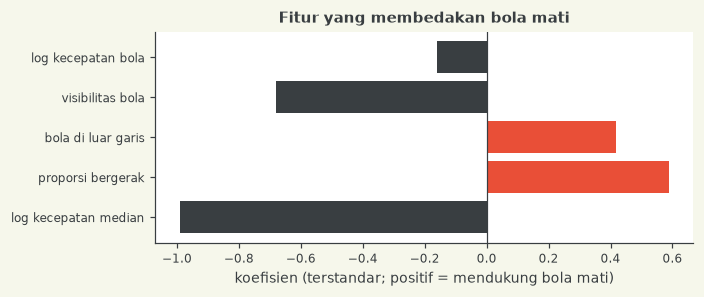

In [4]:
X = FEAT.values
res = []
for tr_h, te_h in ((1, 2), (2, 1)):
    tr, te = (y >= 0) & (HALF == tr_h), (y >= 0) & (HALF == te_h)
    m = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500)).fit(X[tr], y[tr])
    pr = m.predict_proba(X[te])[:, 1]
    res.append({"latih": f"babak {tr_h}", "uji": f"babak {te_h}", "AUC": roc_auc_score(y[te], pr),
                "balanced acc": balanced_accuracy_score(y[te], pr > 0.5), "n mati uji": int((y[te] == 1).sum())})
display(pd.DataFrame(res).round(3))

lab = (y >= 0)
MODEL = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500)).fit(X[lab], y[lab])
coef = pd.Series(MODEL[-1].coef_[0], index=FEAT.columns)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(coef.index, coef.values, color=[C1 if v > 0 else C2 for v in coef.values])
ax.axvline(0, color=INK, lw=0.8); ax.set(xlabel="koefisien (terstandar; positif = mendukung bola mati)", title="Fitur yang membedakan bola mati")
fig.tight_layout(); plt.show()

AUC antar babak hanya sekitar 0,75, jadi detektor ini **lemah** meskipun diuji terhadap pseudo-label-nya sendiri. Dua koefisien sesuai intuisi (kecepatan median rendah dan bola terlihat di luar garis mendukung bola mati; visibilitas bola tinggi menolaknya). Koefisien `proporsi bergerak` justru positif: fitur ini berkolinearitas dengan kecepatan median, sehingga tanda individualnya tidak bisa dibaca sebagai penyebab.

## [4] Probabilitas bola mati sepanjang pertandingan

Model akhir dilatih pada seluruh pseudo-label, lalu diterapkan ke setiap frame. Log-odds $r_t = \mathrm{logit}\, p^{dead}_t$ (dikoreksi ke prior porsi mati pada pseudo-label, karena model dilatih dengan bobot seimbang) dipotong ke $[-6, 6]$ dan menjadi bukti bagi decoder.

prior mati pada pseudo-label: 0.177
p(mati) > 0.5 pada frame dinilai: 4.7% | rata-rata p: 0.179


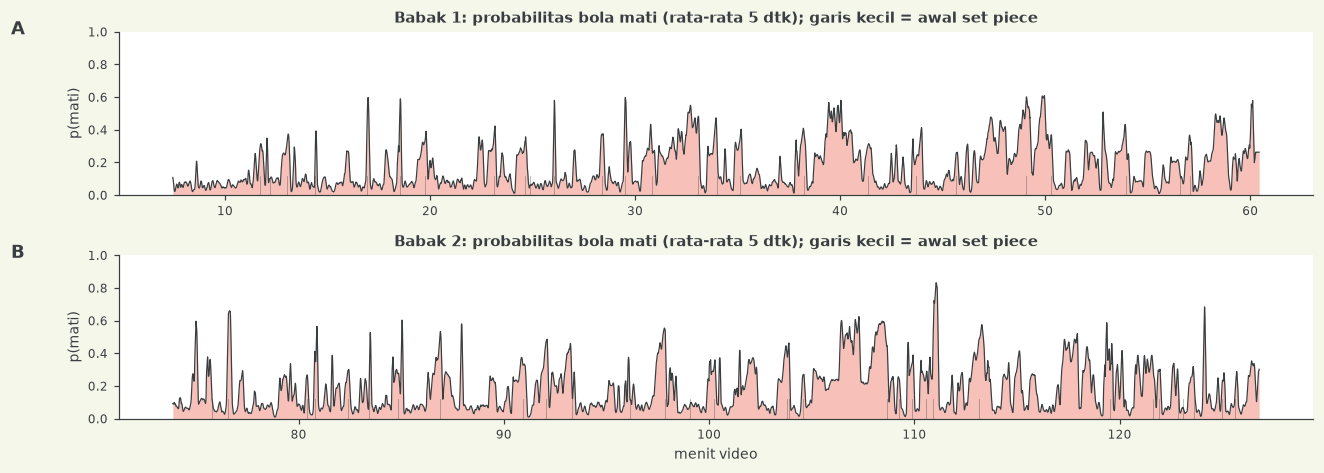

In [5]:
p_bal = np.clip(MODEL.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)           # model berbobot-seimbang: prior sama
prior = (y == 1).sum() / (y >= 0).sum()                                 # porsi mati pada contoh berlabel
R = np.clip(np.log(p_bal / (1 - p_bal)) + np.log(prior / (1 - prior)), -6, 6)   # koreksi prior ke log-odds
p_dead = 1 / (1 + np.exp(-R))
print(f"prior mati pada pseudo-label: {prior:.3f}")
print(f"p(mati) > 0.5 pada frame dinilai: {np.mean(p_dead[GRADED] > 0.5):.1%} | rata-rata p: {p_dead[GRADED].mean():.3f}")

fig, ax = plt.subplots(2, 1, figsize=(12, 4.4), sharex=False)
for a, (h, s, e) in zip(ax, BLOCKS):
    t = np.arange(s, e + 1) / FPS / 60
    pm = pd.Series(p_dead[s:e + 1]).rolling(125, center=True, min_periods=1).mean().values
    a.fill_between(t, pm, color=C1, alpha=0.35, lw=0); a.plot(t, pm, color=C2, lw=0.8)
    for _, r in sp[(sp.start_frame >= s) & (sp.start_frame <= e)].iterrows():
        a.axvline(r.start_frame / FPS / 60, color=INK, lw=0.5, alpha=0.45, ymax=0.12)
    a.set(ylim=(0, 1), ylabel="p(mati)", title=f"Babak {h}: probabilitas bola mati (rata-rata 5 dtk); garis kecil = awal set piece")
ax[1].set_xlabel("menit video"); panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

`p(mati)` jarang melewati 0,6 dan puncaknya tidak jelas berimpit dengan awal set piece (garis kecil di dasar grafik). Detektor ini lebih memberi kecenderungan lemah daripada sinyal yang bisa dipercaya untuk memutuskan satu frame.

## [5] Decoder Viterbi tiga keadaan

Keadaan `H`, `A`, `D`. Bukti tim dari 002 hanya berlaku untuk `H`/`A`. Keadaan `D` tidak membawa informasi tim, sehingga emisinya setara dengan tebakan tim 50/50 ($\log 0{,}5$). Bukti bola mati menambah $+\kappa r_t/2$ untuk `D` dan $-\kappa r_t/2$ untuk `H`/`A`. Skala κ meredam autokorelasi (fitur dihaluskan 50 frame). Biaya pergantian: λ antara `H` dan `A`, μ dari dan ke `D`.

In [6]:
TAU = 3.0
dist = common.team_distances()
dH, dA = dist[:, 0], dist[:, 1]
OK = np.isfinite(dH) & np.isfinite(dA)
E = np.zeros(N); E[OK] = np.clip((dA[OK] - dH[OK]) / TAU, -10, 10)
LP_H, LP_A = -np.logaddexp(0, -E), -np.logaddexp(0, E)
LP_H[~OK] = 0; LP_A[~OK] = 0

def decode(lam=50.0, mu=30.0, kappa=0.04, use_dead=True):
    labels = np.full(N, "X", dtype="<U1")
    cost = np.array([[0, lam, mu], [lam, 0, mu], [mu, mu, 0]], float)
    for half, a, b in BLOCKS:
        r = R[a:b + 1] * kappa if use_dead else np.zeros(b + 1 - a)
        em = np.stack([LP_H[a:b + 1] - r / 2, LP_A[a:b + 1] - r / 2, np.log(0.5) + r / 2], 1)   # D: tanpa info tim = log 0,5
        path = common.viterbi_k(em, cost)
        labels[a:b + 1] = np.array(["H", "A", "D"])[path]
        if half == 2:
            labels[a:KICKOFF2] = "D"
    return labels

def possessions(labels):
    n, durs = 0, []
    for _, a, b in BLOCKS:
        seg = labels[a:b + 1]
        for t in ("H", "A"):
            s, e = common.runs(seg == t); n += len(s); durs += list((e - s) / FPS)
    return n, float(np.mean(durs))

demo = decode()
print(pd.Series(demo[GRADED]).value_counts(normalize=True).round(3).to_string())
print("possession: %d | durasi rata-rata %.1f dtk" % possessions(demo))

H    0.516
A    0.463
D    0.021
possession: 154 | durasi rata-rata 40.4 dtk


Porsi `D` turun dari 38% (aturan gap 002) menjadi sekitar 2%. Itu jauh di bawah porsi bola mati yang wajar (ground truth publik 5 menit sekitar 20%), jadi kini kelas `D` hampir kosong: terlalu sedikit, bukan terlalu banyak.

## [6] Varian yang dibangun

Variasi satu parameter pada satu waktu terhadap konfigurasi dasar (λ = 50, μ = 30, κ = 0,04), ditambah ablasi tanpa bukti bola mati (hanya pra-kick-off) dan baseline `smooth50`.

In [7]:
VARIANTS = {
    "v1_base": dict(),
    "v2_kappa02": dict(kappa=0.02),
    "v3_kappa08": dict(kappa=0.08),
    "v4_mu60": dict(mu=60.0),
    "v5_nodead": dict(use_dead=False),
}
for old in OUT.glob("*.csv"): old.unlink()
rows, LAB = [], {}
for name, kw in VARIANTS.items():
    lab = decode(**kw); LAB[name] = lab
    write_submission(str(OUT / f"{name}.csv"), lab)
    n, d = possessions(lab)
    rows.append({"varian": name, "possession": n, "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(lab[GRADED] == "D"), 1)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, d = possessions(base)
rows.append({"varian": "baseline_smooth50", "possession": n, "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(base[GRADED] == "D"), 1)})
display(pd.DataFrame(rows))

,varian,possession,durasi rata2 (dtk),% D (dinilai)
0,v1_base,154,40.4,2.1
1,v2_kappa02,150,41.1,3.1
2,v3_kappa08,157,39.7,1.9
3,v4_mu60,159,39.2,1.8
4,v5_nodead,140,42.4,6.6
5,baseline_smooth50,594,7.2,32.3


## [7] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil antar varian adalah noise dan tidak boleh dipakai untuk memilih varian.

In [8]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


v1_base.csv -> VALID


v2_kappa02.csv -> VALID


v3_kappa08.csv -> VALID


v4_mu60.csv -> VALID


v5_nodead.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v5_nodead,0.5089,0.3333,7,42.1314
1,2,baseline_smooth50,0.6207,0.3256,26,10.8031
2,3,v1_base,0.5111,0.3200,8,37.5000
3,4,v2_kappa02,0.5111,0.3200,8,37.5000
4,5,v3_kappa08,0.5111,0.3200,8,37.5000
5,6,v4_mu60,0.5111,0.3200,8,37.5000


# Ringkasan 003

**Yang dikerjakan.** Aturan gap → `D` pada 002 diganti detektor bola mati (regresi logistik, 5 fitur kolektif, pseudo-label dari awal set piece dan kick-off pada Smart Tagging) yang bukti log-odds-nya masuk ke Viterbi tiga keadaan H/A/D. Semua enam berkas lolos `validate_submission.py`. Tidak ada label tangan, tidak ada ground truth untuk pelatihan, dan tidak ada data yang keluar dari mesin.

**Hasil: detektornya lemah dan 003 tidak lebih baik daripada 002.**
1. AUC antar babak terhadap pseudo-label hanya 0,75 dan 0,77 (latih babak 1 uji babak 2, dan sebaliknya).
2. `p(mati)` jarang di atas 0,6 dan tidak jelas berimpit dengan awal set piece.
3. Setelah koreksi prior, `D` hanya 2,1% frame dinilai (konfigurasi dasar), jauh di bawah porsi wajar (sekitar 20% pada GT publik). Varian κ (0,02 dan 0,08) dan μ (60) hampir tidak mengubah ini (1,8 sampai 3,1%), sehingga hasilnya tidak sensitif terhadap parameter karena buktinya sendiri kecil.
4. Pada GT publik, 003 mendapat spellF1 0,320 dan macroF1 0,511 untuk semua varian dengan bukti bola mati, turun dari 002 `v2` (0,370 dan 0,628). Namun dengan 7 sampai 8 possession prediksi terhadap 17 sebenarnya, skor ini hanya menandakan bahwa kelas `D` hampir hilang dan possession terlalu panjang. Jangan dipakai untuk memilih varian.

**Penyebab yang masuk akal (belum diuji).**
- Jendela positif ([start − 6, start + 2] dtk) adalah asumsi dari profil kecepatan rata-rata, dan tag set piece berdurasi tetap 35 detik, sehingga pseudo-label berderau.
- Contoh `hidup` mengandung bola mati yang tidak ditandai.
- Fitur kolektif 2 detik tidak membedakan henti permainan dari permainan lambat. Sinyal yang lebih langsung (bola diam di titik restart, pemain berkumpul, wasit) tidak tersedia di ATD.
- Ada artefak: ketika bukti tim hampir nol (|e| ≈ 0) dan bola ada, keadaan `D` menang seri pada `v5_nodead` (6,6% `D` tanpa bukti bola mati sama sekali). Emisi `D` perlu diperbaiki.

**Langkah berikutnya.** Sinyal bola mati dari ATD saja tampaknya tidak cukup. Opsi: (a) perbaiki pseudo-label (selaraskan awal restart dengan kecepatan bola dan pemain per tag), (b) bola di luar garis dengan margin dan durasi, (c) sinyal video lokal (`match_only.mp4`), seperti deteksi bola atau pemain yang berhenti. Sampai saat itu, 002 `v2` tetap acuan terbaik dengan catatan yang sama bahwa tidak ada klaim perbaikan atas baseline.